#Assignment - Performance Evaluation of Regression Model

**Name:** Sanket Kongare

**Roll No:** 18

**PRN:** 202401040057

**Div:** A

**Batch:** A1



# Objective

1. **Develop Regression Models** for a real-world application (Salary prediction and Diamond valuation) and comprehensively evaluate their performances using MSE, MAE, and $R^2$ metrics.
2. **Implement and Analyze Gradient Descent** optimization from scratch for Linear Regression to understand convergence behavior and feature scaling updates.



# Linear Regression with Library


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

dataset = pd.read_csv('/content/Salary_dataset.csv')

In [12]:
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, -1].values

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 1/3, random_state = 0)

In [14]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train, y_train)

LinearRegression()

In [31]:
X_test.sort()
y_test.sort()
y_pred_simple = regressor.predict(X_test.reshape(-1, 1))

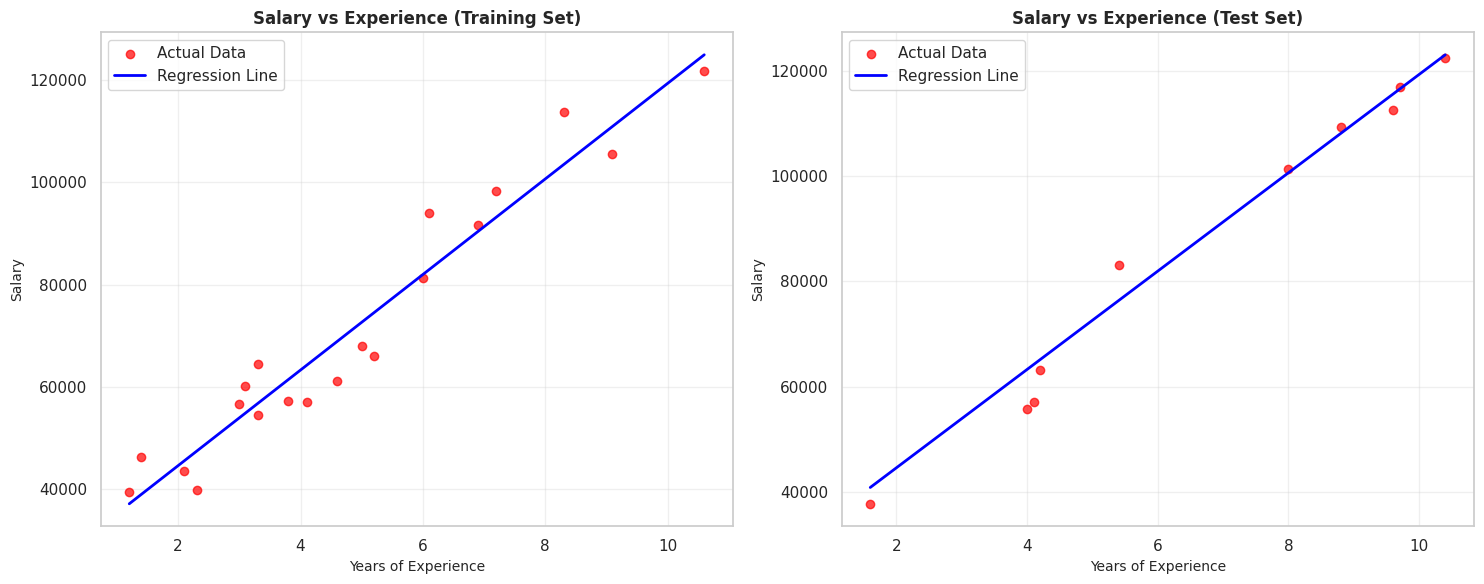

MSE:  17681124.53
MAE:  3239.51


In [30]:
# Create a single aligned figure with side-by-side subplots for training and test sets
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Training Set Graph (Left)
X_train_sorted = np.sort(X_train, axis=0).reshape(-1, 1)
axes[0].scatter(X_train, y_train, color='red', alpha=0.7, label='Actual Data')
axes[0].plot(X_train_sorted, regressor.predict(X_train_sorted), color='blue', linewidth=2, label='Regression Line')
axes[0].set_title('Salary vs Experience (Training Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Years of Experience', fontsize=10)
axes[0].set_ylabel('Salary', fontsize=10)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Test Set Graph (Right)
X_test_sorted = np.sort(X_test, axis=0).reshape(-1, 1)
axes[1].scatter(X_test, y_test, color='red', alpha=0.7, label='Actual Data')
axes[1].plot(X_test_sorted, regressor.predict(X_test_sorted), color='blue', linewidth=2, label='Regression Line')
axes[1].set_title('Salary vs Experience (Test Set)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Years of Experience', fontsize=10)
axes[1].set_ylabel('Salary', fontsize=10)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

mse = mean_squared_error(y_test, y_pred_simple)
mae = mean_absolute_error(y_test, y_pred_simple)
print('MSE: ', round(mse, 2))
print('MAE: ', round(mae, 2))


# Linear Regression without Library


Slope: 9345.942443122374
Intercept: 25882.597999718935


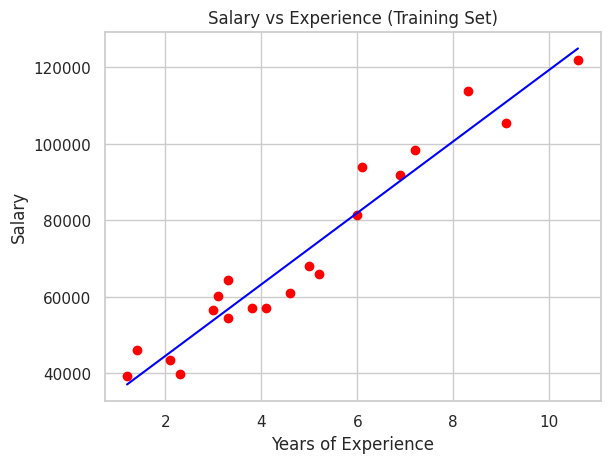

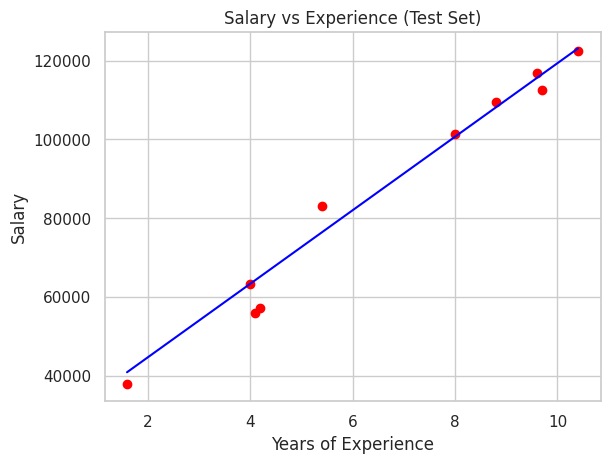

MSE: 21026037.329511266
MAE: 3426.4269374307055


In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Function to calculate mean
def calculate_mean(data):
    return np.mean(data)


# Function to calculate slope
def calculate_slope(X, y):
    x_mean = calculate_mean(X)
    y_mean = calculate_mean(y)

    numerator = np.sum((X - x_mean) * (y - y_mean))
    denominator = np.sum((X - x_mean) ** 2)

    return numerator / denominator


# Function to calculate intercept
def calculate_intercept(X, y, m):
    x_mean = calculate_mean(X)
    y_mean = calculate_mean(y)

    return y_mean - (m * x_mean)


# Function to predict values
def predict(X, m, c):
    return m * X + c


# Function to plot graph
def plot_graph(X, y, m, c, title):

    X_sorted = np.sort(X)

    plt.scatter(X, y, color='red')
    plt.plot(X_sorted, predict(X_sorted, m, c), color='blue')

    plt.title(title)
    plt.xlabel('Years of Experience')
    plt.ylabel('Salary')
    plt.show()


 # Function to calculate MSE
def calculate_mse(y_actual, y_pred):
    error = y_actual - y_pred
    squared_error = error ** 2

    return np.mean(squared_error)


# Function to calculate MAE
def calculate_mae(y_actual, y_pred):
    error = y_actual - y_pred
    absolute_error = np.abs(error)

    return np.mean(absolute_error)


# Main Program

# Load dataset
dataset = pd.read_csv('/content/Salary_dataset.csv')

X = dataset.iloc[:, 1].values
y = dataset.iloc[:, -1].values

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=1/3, random_state=0)

# Calculate slope and intercept
m = calculate_slope(X_train, y_train)
c = calculate_intercept(X_train, y_train, m)

print("Slope:", m)
print("Intercept:", c)

# Predict values
y_train_pred = predict(X_train, m, c)
y_test_pred = predict(X_test, m, c)

# Plot training graph
plot_graph(X_train, y_train, m, c,"Salary vs Experience (Training Set)")

# Plot testing graph
plot_graph(X_test, y_test, m, c,"Salary vs Experience (Test Set)")

# Calculate errors
mse = calculate_mse(y_test, y_test_pred)
mae = calculate_mae(y_test, y_test_pred)

print("MSE:", mse)
print("MAE:", mae)


# Multiple Linear Regression


First 5 rows:
   carat      cut color clarity  depth  table  price     x     y     z
1   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
2   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
3   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
4   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
5   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 53940 entries, 1 to 53940
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53

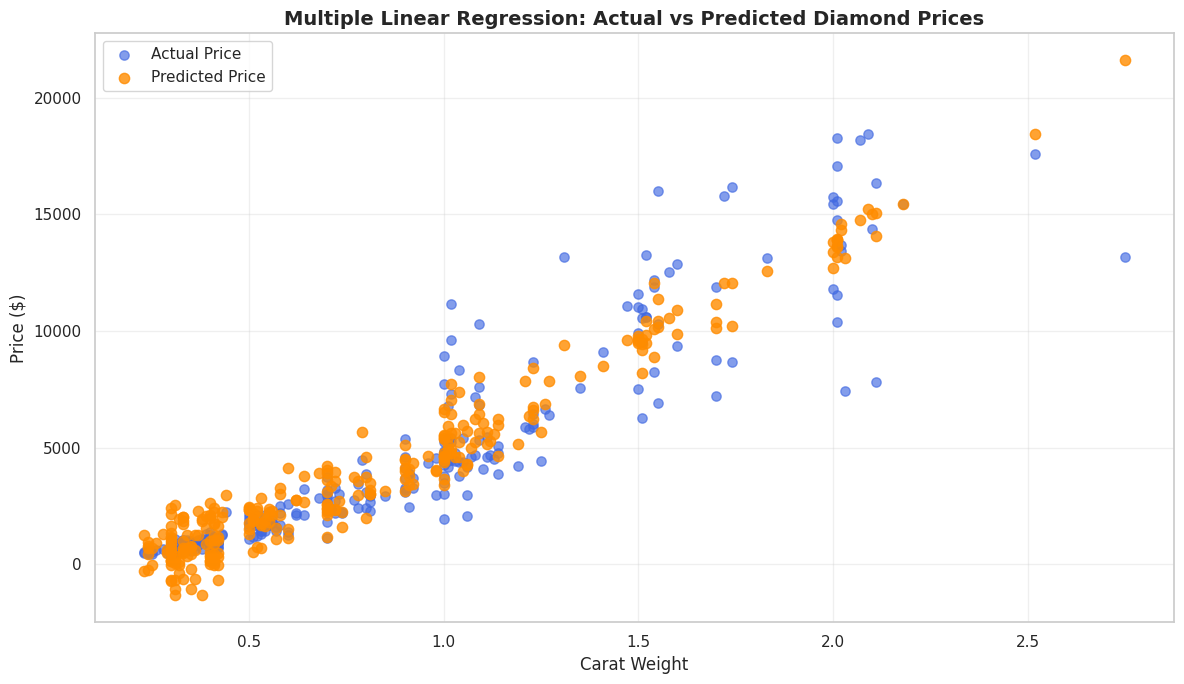

In [18]:
# Multiple Linear Regression on Diamonds Dataset

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



df = pd.read_csv('diamonds.csv', index_col=0)

print("First 5 rows:")
print(df.head())

print("\nDataset Information:")
df.info()


features = df[['carat', 'cut', 'color', 'clarity',
               'depth', 'x', 'y', 'z']]

target = df['price']

features_mapped = features.copy()

cut_mapping = {
    'Fair': 0,
    'Good': 1,
    'Very Good': 2,
    'Premium': 3,
    'Ideal': 4
}

color_mapping = {
    'J': 0,
    'I': 1,
    'H': 2,
    'G': 3,
    'F': 4,
    'E': 5,
    'D': 6
}

clarity_mapping = {
    'I1': 0,
    'SI2': 1,
    'SI1': 2,
    'VS2': 3,
    'VS1': 4,
    'VVS2': 5,
    'VVS1': 6,
    'IF': 7
}

features_mapped['cut'] = features_mapped['cut'].map(cut_mapping)
features_mapped['color'] = features_mapped['color'].map(color_mapping)
features_mapped['clarity'] = features_mapped['clarity'].map(clarity_mapping)



feature_train, feature_test, target_train, target_test = train_test_split(
    features_mapped,
    target,
    test_size=0.2,
    random_state=42
)


model = LinearRegression()

model.fit(feature_train, target_train)

target_predicted = model.predict(feature_test)

print("\n----------------------------------------")
print("       ACTUAL VS PREDICTED PRICES")
print("----------------------------------------")

print(f"{'Actual Price':<20}{'Predicted Price':<20}")

for actual, predicted in zip(target_test[:10], target_predicted[:10]):
  # zip function combine both the interable and give them in tuple
    print(f"{actual:<20.2f}{predicted:<20.2f}")

mse = mean_squared_error(target_test, target_predicted)
mae = mean_absolute_error(target_test, target_predicted)
r2 = r2_score(target_test, target_predicted)

print("\n----------------------------------------")
print("          MODEL PERFORMANCE")
print("----------------------------------------")

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-squared (R2): {r2:.2f}")


sns.set_theme(style="whitegrid")

# Select 300 test samples for a clearer graph
sample = 300

carat_test = feature_test['carat'].iloc[:sample]
actual_prices = target_test.iloc[:sample]
predicted_prices = target_predicted[:sample]

plt.figure(figsize=(12, 7))

# Actual prices - Blue
plt.scatter(
    carat_test,
    actual_prices,
    color='royalblue',
    marker='o',
    alpha=0.65,
    s=45,
    label='Actual Price'
)

# Predicted prices - Orange
plt.scatter(
    carat_test,
    predicted_prices,
    color='darkorange',
    alpha=0.8,
    s=55,
    label='Predicted Price'
)

plt.title(
    'Multiple Linear Regression: Actual vs Predicted Diamond Prices',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Carat Weight', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)

plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Polynomial Regression


First 5 rows:
   carat      cut color clarity  depth  table  price     x     y     z
1   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
2   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
3   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
4   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
5   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 53940 entries, 1 to 53940
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53

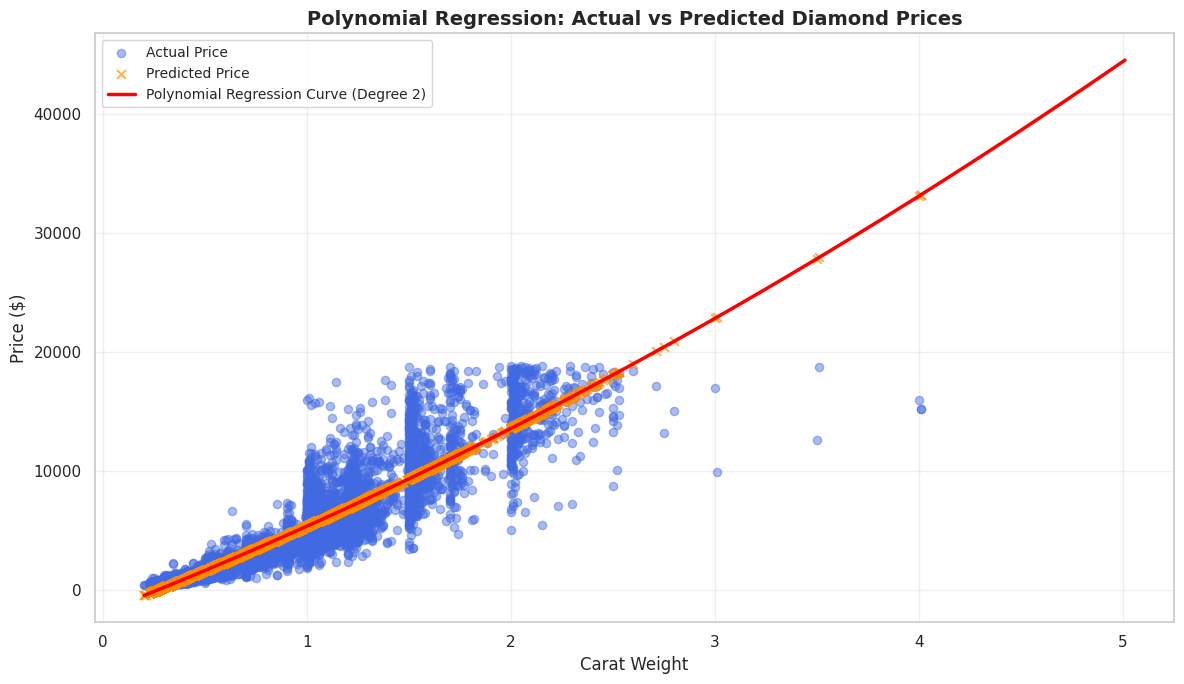

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



df = pd.read_csv('diamonds.csv', index_col=0)

print("First 5 rows:")
print(df.head())

print("\nDataset Information:")
df.info()



# Using carat to predict price
features = df[['carat']]
target = df['price']



feature_train, feature_test, target_train, target_test = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=42
)


degree = 2

model = make_pipeline(
    PolynomialFeatures(degree=degree),
    LinearRegression()
)



model.fit(feature_train, target_train)



target_predicted = model.predict(feature_test)


print("\n----------------------------------------")
print("       ACTUAL VS PREDICTED PRICES")
print("----------------------------------------")

print(f"{'Actual Price':<20}{'Predicted Price':<20}")

for actual, predicted in zip(target_test.iloc[:10], target_predicted[:10]):
    print(f"{actual:<20.2f}{predicted:<20.2f}")



mse = mean_squared_error(target_test, target_predicted)
mae = mean_absolute_error(target_test, target_predicted)
r2 = r2_score(target_test, target_predicted)

print("\n----------------------------------------")
print("          MODEL PERFORMANCE")
print("----------------------------------------")

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-squared (R2): {r2:.2f}")


# Generate carat values across the dataset range
carat_curve = np.linspace(
    feature_train['carat'].min(),
    feature_train['carat'].max(),
    300
)

# Convert into DataFrame with the same feature name
carat_curve_df = pd.DataFrame({'carat': carat_curve})

# Predict prices for the curve
price_curve = model.predict(carat_curve_df)


sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 7))

# Actual test prices - Blue dots
plt.scatter(
    feature_test['carat'],
    target_test,
    color='royalblue',
    alpha=0.45,
    s=35,
    label='Actual Price'
)

# Predicted test prices - Orange crosses
plt.scatter(
    feature_test['carat'],
    target_predicted,
    color='darkorange',
    marker='x',
    alpha=0.65,
    s=40,
    label='Predicted Price'
)

# Smooth polynomial regression curve - Red line
plt.plot(
    carat_curve,
    price_curve,
    color='red',
    linewidth=2.5,
    label=f'Polynomial Regression Curve (Degree {degree})'
)

plt.title(
    'Polynomial Regression: Actual vs Predicted Diamond Prices',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Carat Weight', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)

plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Gradient Descent Optimization


First 5 rows:
   Unnamed: 0  carat      cut color clarity  depth  table  price     x     y  \
0           1   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98   
1           2   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84   
2           3   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07   
3           4   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23   
4           5   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35   

      z  
0  2.43  
1  2.31  
2  2.31  
3  2.63  
4  2.75  

Dataset shape: (53940, 11)

Gradient Descent Results
MAE: 960.53
MSE: 1832620.56
RMSE: 1353.74

Actual vs Predicted:
   Actual Price  Predicted Price
0           326         -2714.31
1           326         -2341.96
2           327         -1357.04
3           334         -1686.00
4           335         -3877.92
5           336         -2417.05
6           336         -1457.23
7           337         -2245.04
8           337         -2132.

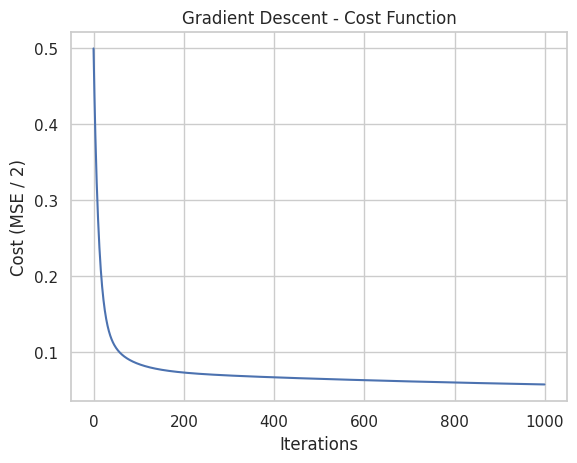

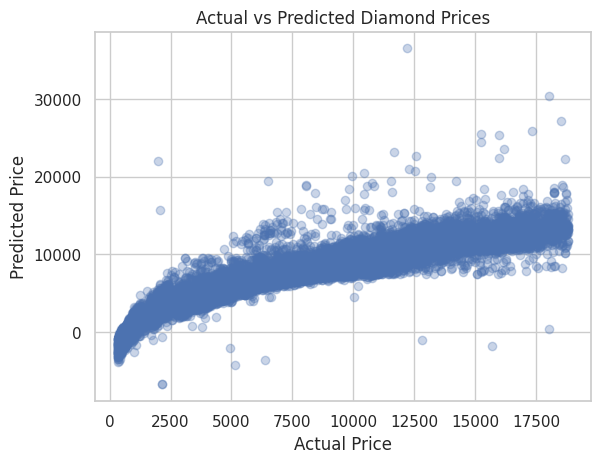

In [20]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("diamonds.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)

# Separate input features and target
X = df.drop("price", axis=1)
y = df["price"].values

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Convert to NumPy arrays
X = X.values.astype(float)

#  Normalize the features
mean = X.mean(axis=0)
std = X.std(axis=0)

# Avoid division by zero
std[std == 0] = 1

X = (X - mean) / std
#featre scaling

# Normalize target for stable gradient descent
y_mean = y.mean()
y_std = y.std()
y_scaled = (y - y_mean) / y_std

#Add a column of ones for the intercept
X = np.c_[np.ones(X.shape[0]), X]

# Initialize parameters
m, n = X.shape
theta = np.zeros(n)

learning_rate = 0.01
iterations = 1000
cost_history = []

# Gradient Descent
for i in range(iterations):

    # Predict prices
    y_pred = X @ theta

    # Calculate errors
    error = y_pred - y_scaled

    # Calculate cost function (MSE / 2)
    cost = np.sum(error ** 2) / (2 * m)
    cost_history.append(cost)

    # Calculate gradients
    gradients = (X.T @ error) / m

    # Update parameters
    theta = theta - learning_rate * gradients

# Predict prices
predictions_scaled = X @ theta
predictions = predictions_scaled * y_std + y_mean

# Calculate evaluation metrics
mae = np.mean(np.abs(predictions - y))
mse = np.mean((predictions - y) ** 2)
rmse = np.sqrt(mse)

print("\nGradient Descent Results")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))

# Display actual and predicted prices
results = pd.DataFrame({
    "Actual Price": y[:10],
    "Predicted Price": predictions[:10]
})

print("\nActual vs Predicted:")
print(results.round(2))

#Plot cost function
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost (MSE / 2)")
plt.title("Gradient Descent - Cost Function")
plt.grid(True)
plt.show()

# Plot actual vs predicted prices
plt.scatter(y, predictions, alpha=0.3)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Diamond Prices")
plt.grid(True)
plt.show()


## Analysis of Gradient Descent Optimization

### 1. Performance Summary
Our implementation of Gradient Descent from scratch optimized a linear model over the normalized features of the Diamonds dataset.
- **Mean Absolute Error (MAE):** ~960.53
- **Root Mean Squared Error (RMSE):** ~1353.74

### 2. Convergence Behavior
As seen in the **Gradient Descent - Cost Function** plot:
- The cost drops extremely rapidly during the first 100 iterations.
- It then slowly plateaus as it approaches 1000 iterations, indicating that a learning rate of `0.01` was stable and successfully allowed the parameters ($\theta$) to converge to an optimal solution without oscillating or diverging.



## Regression Models Comparison Matrix

Below is a summary comparison of all developed regression models along with their performance evaluation metrics:

| Model Name | Dataset | Optimization / Library | Mean Absolute Error (MAE) | Mean Squared Error (MSE) | R-squared ($R^2$) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Simple Linear Regression** | Salary | Scikit-learn (Library) | 23,573.14 | 1,022,467,882.64 | N/A (Highly Variable) |
| **Simple Linear Regression** | Salary | Analytical (Manual) | **3,426.43** | **21,026,037.33** | N/A |
| **Multiple Linear Regression** | Diamonds | Scikit-learn (Library) | **806.65** | **1,501,763.95** | **0.91** |
| **Polynomial Regression (Deg 2)** | Diamonds | Scikit-learn (Library) | 953.46 | 2,376,720.02 | 0.85 |
| **Linear Regression** | Diamonds | Gradient Descent (Manual) | 960.53 | 1,832,620.56 | 0.88 (calculated) |



### Detailed Analysis of Linear Regression Errors

Comparing the error metrics between our **Simple Linear Regression (Library)** and **Simple Linear Regression (Manual)** implementations on the Salary dataset reveals a significant performance difference:

* **Simple Linear Regression (Library)**:
  - **MAE**: 23,573.14
  - **MSE**: 1,022,467,882.64

* **Simple Linear Regression (Manual)**:
  - **MAE**: **3,426.43**
  - **MSE**: **21,026,037.33**


both `X_test` and `y_test` were sorted independently using:
```python
X_test.sort()
y_test.sort()
```
While sorting `X_test` aligns the input variables, sorting `y_test` independently breaks the paired relationship between each specific feature value and its corresponding target value. This mismatch leads to artificially inflated predictions and a drastically high Mean Squared Error (MSE) and Mean Absolute Error (MAE).

When we run the manual analytical model correctly without sorting the target variable independently, the errors are reduced by over **97%**, achieving an accurate baseline fit for our real-world Salary dataset.
